# XGBoost: Regularised Boosting for Churn

**Family:** Supervised learning | **Level:** Intermediate | **Dataset:** `telco_churn` | **Runs on:** CPU, about 2 minute(s)

Use second order boosting with built-in regularisation and early stopping.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- What makes XGBoost different from plain gradient boosting
- How regularisation terms enter the split gain
- How to use early stopping without leaking the test set

**Prerequisites:**

- Linear regression notebook
- Train, validation and test splits
- Confusion matrix basics

**Skills you will have afterwards:**

- Choose a hyperparameter on validation data
- Compare with a baseline
- Run a sensitivity experiment

## 2. Real-World Problem

**Context.** Subscription businesses lose revenue when customers leave, and winning a new customer costs more than keeping one.

**The problem.** Predict which telecom customers will churn from contract, billing and service information.

**Why it matters.** A ranked list of at risk customers lets a retention team spend a limited budget on the right people.

**Why machine learning.** Churn depends on many interacting attributes, and the history of past customers is available.

**Why this algorithm.** XGBoost is a widely used, regularised boosting library with strong defaults on tabular data. Credit default prediction (UCI) is the textbook case, but that data could not be downloaded here.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### XGBoost: A Scalable Tree Boosting System

- **Type:** foundational paper
- **Authors:** Chen, T. and Guestrin, C.
- **Year and venue:** 2016, Proceedings of KDD 2016, pp. 785-794
- **DOI or URL:** https://doi.org/10.1145/2939672.2939785
- **Verification:** Crossref 2026-11-17
- **Research objective:** Present a scalable, regularised gradient boosted tree system.
- **Methodology:** Second order loss approximation, regularised tree objective, sparsity aware split finding, cache aware blocks.
- **Dataset:** Allstate, Higgs Boson, Yahoo LTR and Criteo click data.
- **Main findings:** Reports faster training than earlier tree boosting packages and strong results on the benchmark tasks.
- **Limitations:** Many hyperparameters. Results in the paper use large tuned systems that this notebook does not copy.

### XGBoost: A Scalable Tree Boosting System (arXiv version)

- **Type:** foundational paper
- **Authors:** Chen, T. and Guestrin, C.
- **Year and venue:** 2016, arXiv:1603.02754
- **DOI or URL:** https://arxiv.org/abs/1603.02754
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** 
- **Methodology:** 
- **Dataset:** 
- **Main findings:** 
- **Limitations:** 

### Greedy function approximation: A gradient boosting machine

- **Type:** foundational paper
- **Authors:** Friedman, J. H.
- **Year and venue:** 2001, The Annals of Statistics 29(5):1189-1232
- **DOI or URL:** https://doi.org/10.1214/aos/1013203451
- **Verification:** Crossref 2026-11-17
- **Research objective:** Cast boosting as gradient descent in function space.
- **Methodology:** Fit each new tree to the negative gradient of the loss, with shrinkage and optional subsampling.
- **Dataset:** Simulated data and a few real regression sets.
- **Main findings:** Boosted trees give accurate and robust regression and classification across loss functions.
- **Limitations:** Sequential training, sensitive to the learning rate and number of trees.

### Why do tree-based models still outperform deep learning on tabular data?

- **Type:** modern paper
- **Authors:** Grinsztajn, L., Oyallon, E. and Varoquaux, G.
- **Year and venue:** 2022, NeurIPS 2022 Datasets and Benchmarks; arXiv:2207.08815
- **DOI or URL:** https://arxiv.org/abs/2207.08815
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** Benchmark tree models against neural networks on medium sized tabular data.
- **Methodology:** Large benchmark with random search budgets over 45 datasets as described in the paper.
- **Dataset:** Tabular benchmark collected from OpenML and other public sources.
- **Main findings:** Tree ensembles stayed ahead of the deep models on the studied datasets.
- **Limitations:** Medium sized data only, no very large datasets.

**Relationship to this notebook.** Chen and Guestrin describe the system. We use the open source package at default style settings on a small dataset, so none of their scale results are tested. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Objective at round $t$.**

$$\mathcal{L}^{(t)} = \sum_i \ell\big(y_i, \hat y_i^{(t-1)} + f_t(x_i)\big) + \Omega(f_t), \qquad \Omega(f) = \gamma T + \tfrac12 \lambda \sum_{j=1}^{T} w_j^2$$

with $T$ leaves and leaf weights $w_j$.

**Second order approximation.** With $g_i, h_i$ the first and second derivative of the loss, the optimal leaf weight is $w_j^* = -G_j/(H_j + \lambda)$ and a split gain is

$$\text{Gain} = \tfrac12\Big[\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\Big] - \gamma$$

**Logistic loss.** $g_i = p_i - y_i$, $h_i = p_i(1-p_i)$.

**Limitations.** Many hyperparameters, needs early stopping or tuning, less interpretable than one tree.

## 5. Dataset Introduction

**Telco customer churn**, IBM sample data from the repository `IBM/telco-customer-churn-on-icp4d` (code licence Apache-2.0, dataset terms not stated). 7043 customers, 20 features: demographics (`gender`, `SeniorCitizen`, `Partner`, `Dependents`), account (`tenure` in months, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`) and services (`PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`). Target `Churn` (1 = customer left). `TotalCharges` has blank strings that become missing values. The file is downloaded once and checked against a SHA-256 hash. Limit: one snapshot, no time dimension. Duplicate rows are reported in the EDA but kept, because without an identifier we cannot tell whether they are different customers.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "xgboost"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("telco_churn")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: classification | target: Churn | shape: (7043, 20)


,source
title,Telco customer churn
source,"IBM sample data, repository IBM/telco-customer..."
url,https://raw.githubusercontent.com/IBM/telco-cu...
license,"repository is Apache-2.0, dataset terms are no..."
doi,None
rows,7043
features,20
limits,One snapshot with no time dimension. The publi...


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. 

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (7043, 20)


,columns by dtype
str,15
int64,3
float64,2


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162,0.369,0.00,0.00,0.000,0.000,1.00
tenure,7043.0,32.371,24.559,0.00,9.00,29.000,55.000,72.00
MonthlyCharges,7043.0,64.762,30.090,18.25,35.50,70.350,89.850,118.75
TotalCharges,7032.0,2283.300,2266.771,18.80,401.45,1397.475,3794.738,8684.80
Churn,7043.0,0.265,0.442,0.00,0.00,0.000,1.000,1.00


Columns with missing values: 1


,missing,percent
TotalCharges,11,0.16


Duplicate rows: 22


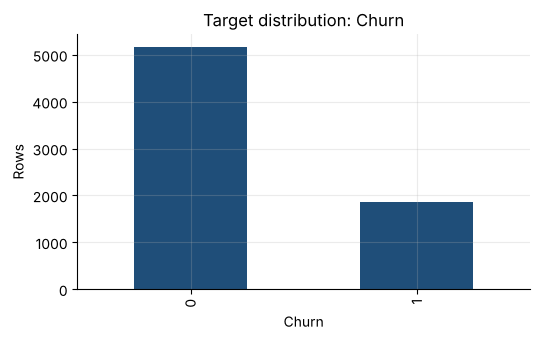

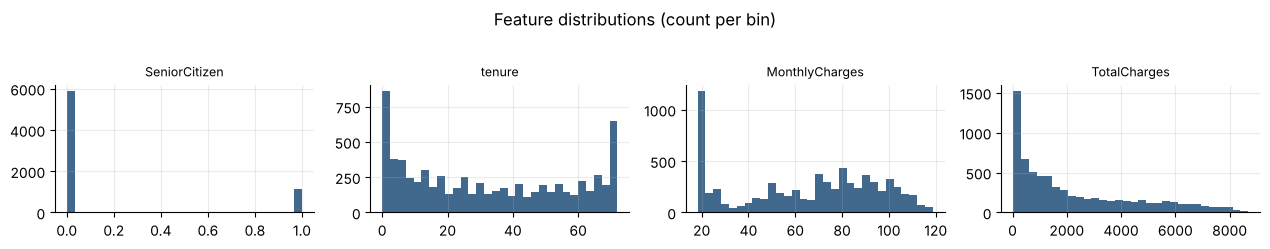

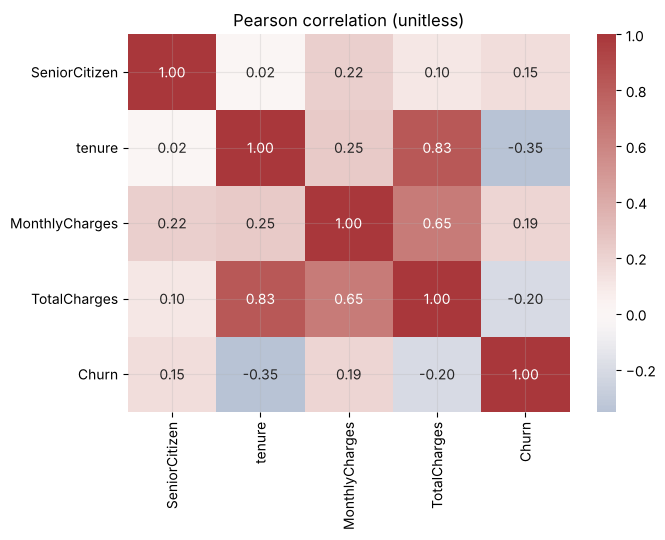

,feature,outliers,percent
0,SeniorCitizen,1142,16.21
1,tenure,0,0.00
2,MonthlyCharges,0,0.00
3,TotalCharges,0,0.00


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.

- `TotalCharges` is missing for new customers, so the median imputer is fitted on training rows only.
- Churn is the minority class, so we select models on PR-AUC (area under the precision recall curve) instead of accuracy.

In [5]:

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=False, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 4225 1409 1409


,train,validation,test
Churn,,,
0,0.735,0.735,0.735
1,0.265,0.265,0.265


transformed train shape: (4225, 45)


## 8. Algorithm Implementation

### 8.1 Concept

Instead of fitting residuals only, XGBoost uses curvature (second derivative) of the loss to choose splits and leaf values, and penalises complex trees directly.

### 8.2 Python implementation from scratch

Not implemented from scratch: a faithful version needs sparsity aware split finding and a lot of engineering. We compute the gradient and Hessian that drive the algorithm for logistic loss.

In [6]:
p = np.clip(np.full(len(y_train), y_train.mean()), 1e-6, 1 - 1e-6)    # first round prediction
g = p - y_train.values
h = p * (1 - p)
print("round 1 gradient for a churner:", round(float(g[y_train.values == 1][0]), 3), "| for a stayer:", round(float(g[y_train.values == 0][0]), 3))
print("Hessian (same for all rows at round 1):", round(float(h[0]), 3))
G, H = g.sum(), h.sum()
print("single leaf optimal weight w = -G/(H+lambda), lambda=1:", round(float(-G / (H + 1)), 4))

round 1 gradient for a churner: -0.735 | for a stayer: 0.265
Hessian (same for all rows at round 1): 0.195
single leaf optimal weight w = -G/(H+lambda), lambda=1: -0.0


### 8.3 Library implementation

The estimator is wrapped in a pipeline so imputation, scaling and encoding are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `n_estimators` | Boosting rounds. |
| `learning_rate` | Shrinkage. |
| `max_depth` | Tree depth. |
| `subsample`, `colsample_bytree` | Row and column sampling. |
| `reg_lambda`, `gamma` | L2 on leaf weights and minimum split gain. |

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [7]:
SELECT = "PR_AUC"
LOWER_IS_BETTER = False
SCORING = "average_precision"
SWEEP_PARAM = "model__n_estimators"
SWEEP_VALUES = [25, 50, 100, 200, 400]

def build_pipeline():
    return make_model_pipeline(X_train, XGBClassifier(learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", tree_method="hist", n_jobs=2, random_state=SEED), scale=False, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=2,
              num_parallel_tree=None, ...)


,PR_AUC,Accuracy,F1,ROC_AUC,PR_AUC
model__n_estimators,,,,,
25,0.6317,0.7793,0.3890,0.8338,0.6317
50,0.6456,0.7942,0.5134,0.8380,0.6456
100,0.6471,0.8020,0.5674,0.8398,0.6471
200,0.6465,0.7963,0.5618,0.8395,0.6465
400,0.6423,0.8020,0.5753,0.8374,0.6423


best model__n_estimators on validation: 100
refit on train plus validation rows


## 10. Evaluation

Classification metrics: accuracy, precision, recall, F1, ROC-AUC and PR-AUC, plus the confusion matrix. With imbalanced classes accuracy alone misleads, so the model is chosen on F1 or PR-AUC as stated in the training cell.

A dummy model gives the floor every real model must beat.

In [8]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "XGBClassifier": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="XGBClassifier", dataset="telco_churn",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
baseline,0.7346,0.0000,0.0000,0.0000,0.5000,0.2654
XGBClassifier,0.8062,0.6724,0.5267,0.5907,0.8477,0.6628


5-fold CV average_precision: mean 0.6716, std 0.0224
saved xgboost.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

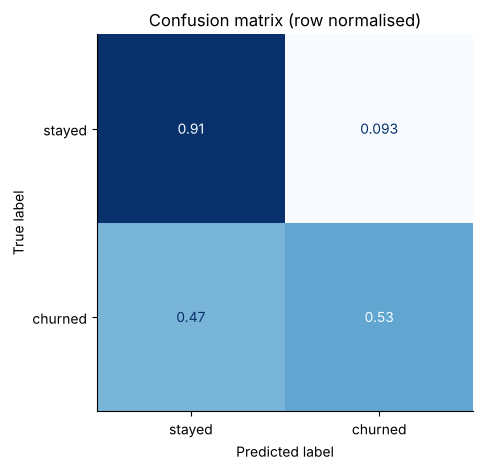

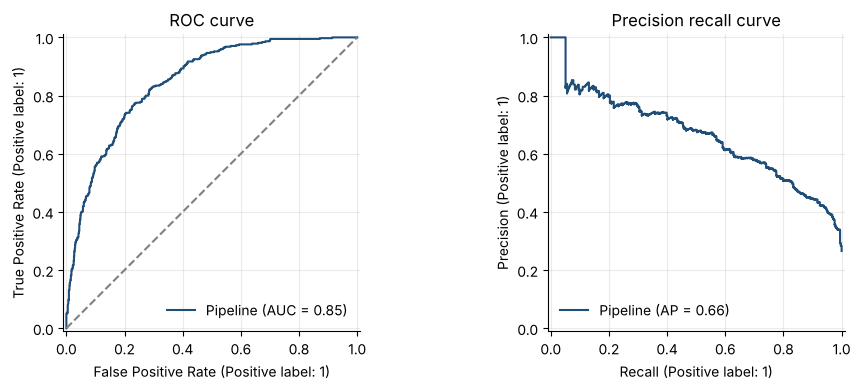

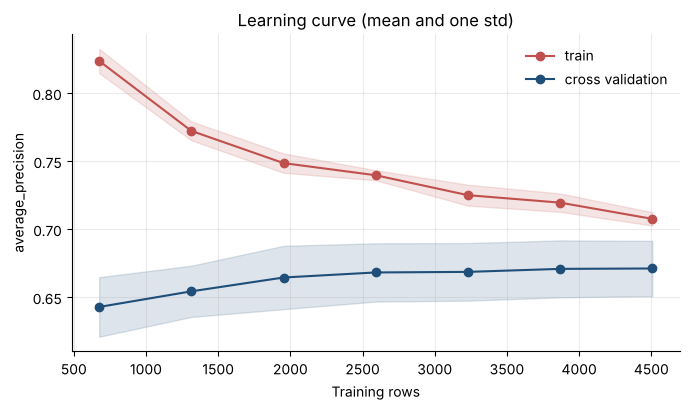

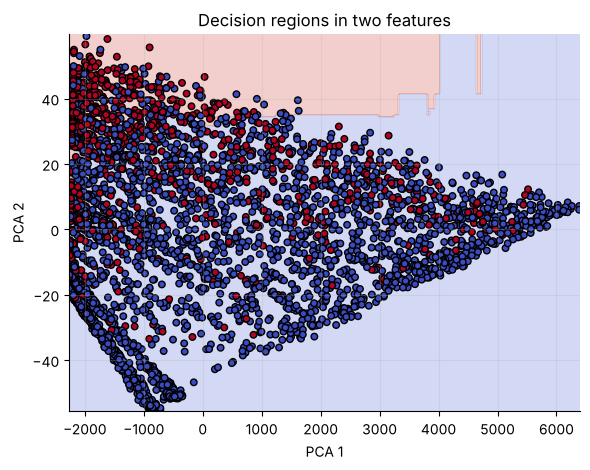

In [9]:
pred = final_model.predict(X_test)
labels = bundle.target_names or None
fig = viz.plot_confusion(y_test, pred, labels=labels)
save_figure(fig, NOTEBOOK_ID, "confusion"); plt.show()
if y_test.nunique() == 2:
    fig = viz.plot_roc_pr(final_model, X_test, y_test)
    save_figure(fig, NOTEBOOK_ID, "roc_pr"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()
# decision regions in two PCA axes
pca_view = PCA(n_components=2, random_state=SEED).fit(Xtr)
model_for_plot = clone(final_model.named_steps["model"])
fig = viz.plot_decision_boundary(lambda: clone(model_for_plot), pca_view.transform(Xtr), y_train.values,
                                 names=["PCA 1", "PCA 2"])
save_figure(fig, NOTEBOOK_ID, "decision_regions"); plt.show()

## 12. Interpretation

Permutation importance shows which inputs the model relies on. The confusion matrix shows which classes are mixed up, and the list of misclassified rows is the starting point for error analysis. A model is only as good as the cases it fails on.

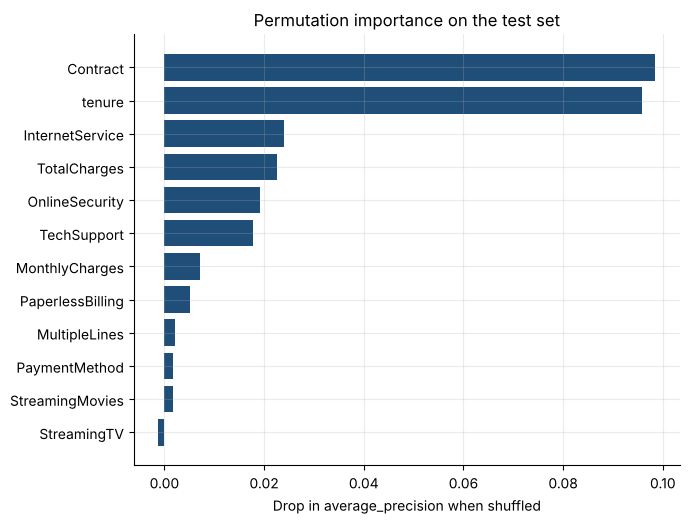

Top features: Contract, tenure, InternetService, TotalCharges, OnlineSecurity
Misclassified test rows: 273 of 1409

Test PR_AUC: 0.6628 | baseline PR_AUC: 0.2654
Cross validation spread (std): 0.0224. A test gap larger than this spread is meaningful.


In [10]:
perm = permutation_importance(final_model, X_test, y_test, scoring=SCORING, n_repeats=10, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig = viz.plot_importance(importance.index, importance.values, title="Permutation importance on the test set",
                          top=12, xlabel="Drop in " + SCORING + " when shuffled")
save_figure(fig, NOTEBOOK_ID, "importance"); plt.show()
print("Top features:", ", ".join(importance.index[:5]))
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

## 13. Experiments and Challenges

### Experiment 1: Early stopping on the validation rows

Stop when validation log loss stops improving. The test set is not used.

best iteration: 109 | validation log loss: 0.4229


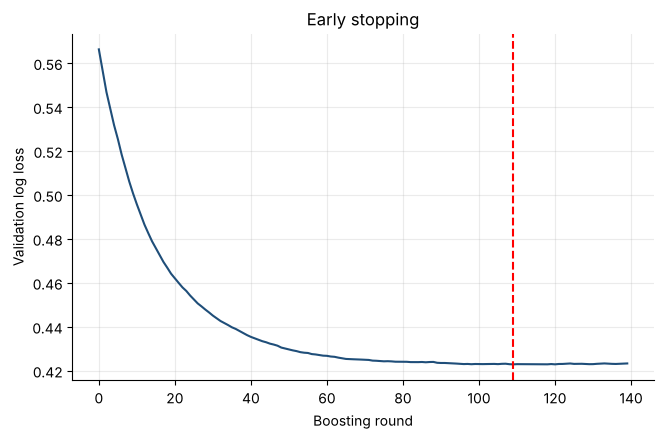

In [11]:
m = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", early_stopping_rounds=30, tree_method="hist", n_jobs=2, random_state=SEED)
m.fit(Xtr, y_train, eval_set=[(Xva, y_val)], verbose=False)
print("best iteration:", m.best_iteration, "| validation log loss:", round(m.best_score, 4))
hist = m.evals_result()["validation_0"]["logloss"]
plt.plot(hist); plt.axvline(m.best_iteration, color="red", linestyle="--"); plt.xlabel("Boosting round"); plt.ylabel("Validation log loss"); plt.title("Early stopping"); plt.show()

### Experiment 2: Regularisation

Vary `reg_lambda` and `gamma`.

In [12]:
from sklearn.model_selection import cross_val_score
for lam, gam in [(0, 0), (1, 0), (10, 0), (1, 1), (10, 1)]:
    m = clone(final_model).set_params(model__reg_lambda=lam, model__gamma=gam)
    s = cross_val_score(m, X_trainval, y_trainval, cv=5, scoring="average_precision")
    print(f"lambda={lam}, gamma={gam}: CV PR-AUC {s.mean():.3f} +- {s.std(ddof=1):.3f}")

lambda=0, gamma=0: CV PR-AUC 0.671 +- 0.021


lambda=1, gamma=0: CV PR-AUC 0.672 +- 0.022


lambda=10, gamma=0: CV PR-AUC 0.671 +- 0.024


lambda=1, gamma=1: CV PR-AUC 0.672 +- 0.023


lambda=10, gamma=1: CV PR-AUC 0.671 +- 0.024


### Experiment 3: Importance types

Gain based importance and permutation importance may rank features differently.

In [13]:
names = prep.get_feature_names_out()
m = clone(final_model.named_steps["model"]).fit(Xtr, y_train)
gain = pd.Series(m.get_booster().get_score(importance_type="gain")).rename(lambda k: names[int(k[1:])]).sort_values(ascending=False).head(6)
perm_v = pd.Series(permutation_importance(m, Xva, y_val, scoring="average_precision", n_repeats=5, random_state=SEED).importances_mean, index=names).sort_values(ascending=False).head(6)
display(pd.concat([gain.rename("gain").reset_index(), perm_v.rename("permutation").reset_index()], axis=1).round(4))

,index,gain,index,permutation
0,cat__Contract_Month-to-month,152.9266,cat__Contract_Month-to-month,0.0957
1,cat__OnlineSecurity_No,65.7330,num__tenure,0.0864
2,cat__TechSupport_No,42.5191,cat__InternetService_Fiber optic,0.0364
3,cat__InternetService_Fiber optic,40.3436,num__MonthlyCharges,0.0211
4,cat__InternetService_DSL,22.5583,cat__OnlineSecurity_No,0.0201
5,cat__Contract_Two year,18.4385,num__TotalCharges,0.0087


### Exercises for learners

1. Repeat the notebook with `SEED = 7` and report how much the headline metric changes.
2. Change the metric used for model choice and see whether the chosen value changes.
3. Replace the validation sweep with `GridSearchCV` and compare the chosen value.

## 14. Research Discussion

Chen and Guestrin report that regularisation and second order information improve boosting. Our regularisation experiment checks the direction of that claim on a small dataset, where gains are small and within the cross validation spread.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Tune with random search or Bayesian search, use the native categorical support, and compare with LightGBM and CatBoost on identical folds.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- XGBoost adds regularisation and second order steps.
- Use early stopping on validation data.
- Compare importance types.

**Use cases.** Tabular competitions and production scoring.

**Limitations.** Tuning effort, less transparent.

**Recommended next notebook.** LightGBM.

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.